# Customer churn prediction — synthetic demonstration

This public notebook executes the same quality/preparation/modeling rules on fictional inputs. All displayed metrics and figures are **synthetic-demo evidence**, not the historical private assessment. No original records, prompt, saved results or trained private models are used. Source functions live in `src/`; this is a repository notebook, not the private submission notebook.

## 1. Set up and generate fictional inputs

Run from the repository root or `notebooks/` with the pinned Python stack. Seed 42 controls generated histories and estimators. Customer identifiers start with SYN-. Input generation intentionally includes source-shaped anomalies and fallback cases; these are invented test scenarios. A generated synthetic brief keeps the existing three-input provenance interface without redistributing the original prompt.

In [1]:
from pathlib import Path
import os
import sys
import importlib.metadata
import platform

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src/generate_demo_data.py").is_file():
    raise FileNotFoundError("Run this notebook from the repository root or notebooks/.")
sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))

import numpy as np
import pandas as pd
from IPython.display import display, Image
from src.generate_demo_data import generate_demo_data
from src.audit_data import sha256
from src.eda import generate_eda
from src.prepare_data import generate_preparation
from src.development_review import generate_review
from src.train_models import generate_training
from src.evaluate_model import generate_evaluation
from src.finalize_submission import generate_submission, validate_submission

OUTPUT = ROOT / "outputs"
PREPARATION = OUTPUT / "preparation"
REVIEW = OUTPUT / "development_review"
MODELS = OUTPUT / "models"
EVALUATION = OUTPUT / "evaluation"
FINAL = OUTPUT / "submission"
demo = generate_demo_data(ROOT / "input")
display(pd.DataFrame([demo]))
print("Python:", platform.python_version())
print({name: importlib.metadata.version(name) for name in ("pandas", "numpy", "scikit-learn", "matplotlib")})

,data_kind,seed,training_rows,training_customers,validation_rows,validation_customers
0,synthetic,42,2580,1202,543,241


Python: 3.12.14
{'pandas': '3.0.6', 'numpy': '2.5.3', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2'}


## 2. Audit before defining usable history

Read IDs as strings, normalize internal column names and preserve literal NA. Diagnose date/TENURE disagreements and signed/tiny amounts. No invoice deduplication is performed because multiple products can share a checkout. The source token `noise=True` denotes the fictional positive class.

,Dataset,Rows,Customers,Negative TENURE rows
0,training.csv,2580,1202,1
1,validation.csv,543,241,0


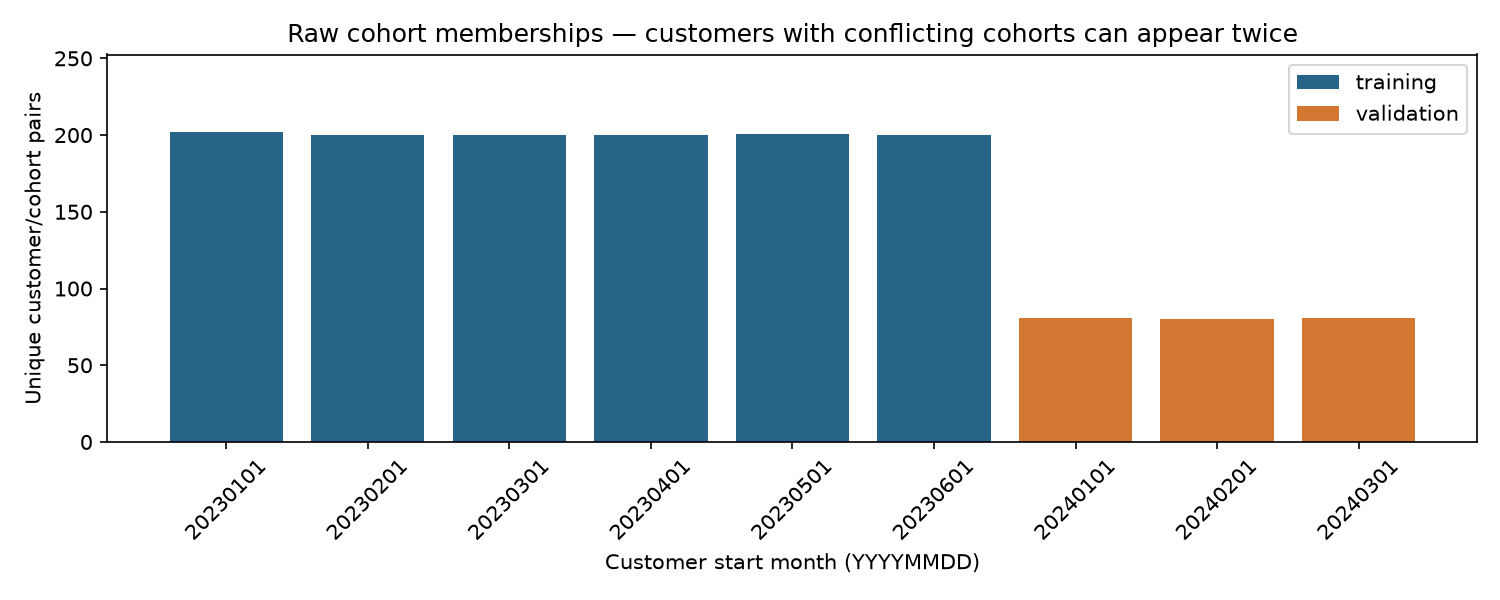

In [2]:
quality = generate_eda(ROOT / "input", OUTPUT)
display(pd.DataFrame([
    {"Dataset": name, "Rows": values["rows"], "Customers": values["customers"],
     "Negative TENURE rows": values["tenure"]["negative_rows"]}
    for name, values in quality["datasets"].items()
]))
display(Image(filename=str(OUTPUT / "figures/cohorts.png")))

*Figure 1 — synthetic acquisition cohorts.* Shape does not establish an annual seasonal cycle. The proposed scoring cutoff is after the two acquisition calendar months; this is not a measured warning before an event.

## 3. Apply the quality policy and construct features

Require TENURE 0/1 **and** checkout in `[start, start + 2 months)`. Exclude ambiguous/shared labeled identities while preserving every scoring identity. Keep metadata/targets separate from predictors. Missing months stay missing until fitted imputation. Learn the evaluation product vocabulary only from usable January–April customers.

Features cover business/acquisition attributes, month coverage, distinct activity, signed record-MRR summaries, product presence and month-to-month changes. IDs, dates, target, role and fallback flags are never predictors.

In [3]:
preparation = generate_preparation(ROOT / "input", PREPARATION)
display(pd.DataFrame(preparation["partitions"]))
display(pd.DataFrame([preparation["identity_exclusions"]]))
print("Prepared predictor count:", len(preparation["predictor_columns"]))

,partition,customers,usable_customers,fallback_customers
0,learning,800,720,80
1,development,200,180,20
2,evaluation,200,180,20


,mixed_cohort_training_customers,shared_training_customers,union_training_customers
0,1,1,2


Prepared predictor count: 27


## 4. Review learning/development distributions

January–April learn transformations and estimators. May supports candidate, fallback-policy and threshold decisions. June assesses the frozen procedure. Cohorts share no eligible labeled customers. Compare class prevalence and missing-history populations before selecting weighting. The conditional fallback prior uses learning labels from customers also lacking usable history.

,partition,scope,customers,retained,churn,churn_rate
0,learning,all,800,406,394,0.4925
3,development,all,200,104,96,0.4800


,policy,learning_customers,probability,fixed_threshold,development_fallback_customers,prediction,tn,fp,fn,tp,accuracy,brier_score
0,global_learning_prior,800,0.4925,0.5,20,0,16,0,4,0,0.8,0.2456
1,learning_fallback_prior,80,0.2000,0.5,20,0,16,0,4,0,0.8,0.1600


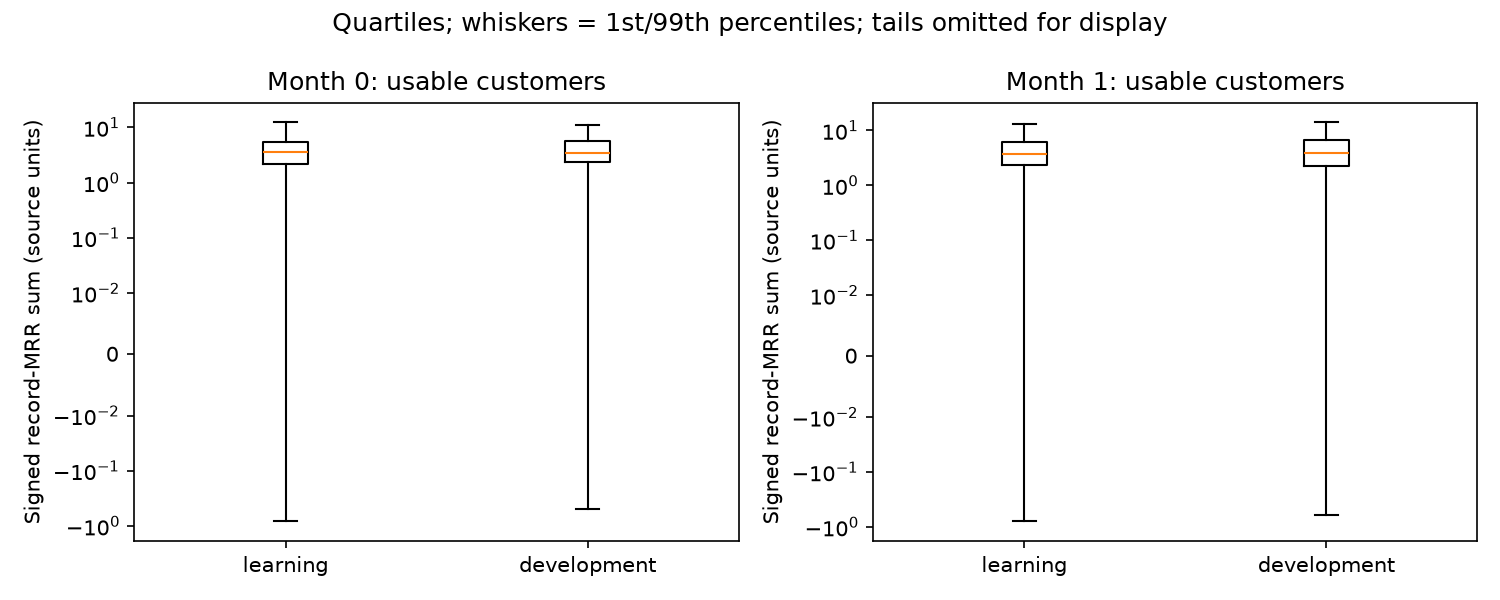

In [4]:
review = generate_review(PREPARATION, REVIEW)
display(pd.read_csv(REVIEW / "class_distribution.csv").query("scope == 'all'").round(4))
display(pd.read_csv(REVIEW / "fallback_comparison.csv").round(4))
display(Image(filename=str(REVIEW / "mrr_quantiles.png")))

*Figure 2 — synthetic signed record-MRR distributions.* Quartiles and 1st/99th-percentile whiskers expose skew without clipping model inputs. The amounts do not represent real revenue or an established accounting mechanism.

## 5. Compare simple models and freeze the decision rule

Compare logistic regression (C=1), a tree (depth 3, leaf 50) and a forest (200 trees, depth 6, leaf 20), each unweighted/balanced. Pipelines learn medians and one-hot categories on usable learning only; only logistic regression also learns scaling. Compare all candidates on the full May population, including fallback, against a constant majority reference.

Select by full-May ROC-AUC. Exact ties use balanced accuracy at 0.5, then family and weighting preferences. Separately select the threshold by May balanced accuracy on 0..1 by 0.01; ties prefer nearest 0.5 then lower. F1 evaluates precision/recall at a cutoff and omits true negatives, so it can favor different choices. No objective is claimed to optimize business costs. The synthetic winner/cutoff need not match the historical private exercise.

,candidate,roc_auc,balanced_accuracy,accuracy,f1,retained_recall
0,logistic_unweighted,0.5621,0.5381,0.535,0.5592,0.4615
3,logistic_balanced,0.5615,0.5148,0.515,0.5026,0.5192
6,tree_unweighted,0.5397,0.5473,0.540,0.6034,0.3654
9,tree_balanced,0.5397,0.5304,0.525,0.5740,0.3942
12,forest_unweighted,0.5678,0.5497,0.545,0.5845,0.4327
15,forest_balanced,0.5671,0.5501,0.550,0.5408,0.5481
18,majority_baseline,0.5000,0.5000,0.520,0.0000,1.0000


Synthetic selected procedure: forest_unweighted threshold: 0.4


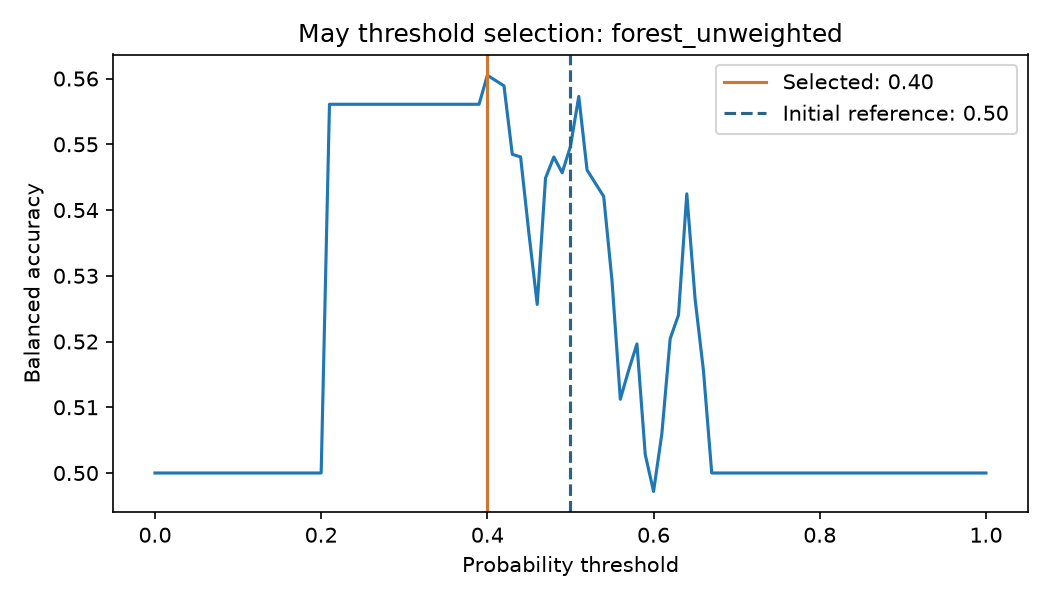

In [5]:
selection = generate_training(PREPARATION, MODELS)
comparison = pd.read_csv(MODELS / "comparison_metrics.csv")
display(comparison.query("scope == 'all'")[
    ["candidate", "roc_auc", "balanced_accuracy", "accuracy", "f1", "retained_recall"]].round(4))
print("Synthetic selected procedure:", selection["selected_candidate"], "threshold:", selection["threshold"])
display(Image(filename=str(MODELS / "threshold_search.png")))

*Figure 3 — synthetic May threshold selection.* Development performance is optimistic because it supports decisions. The selected fit, representation, prior and threshold are now frozen. June will not choose new settings.

## 6. Assess the frozen procedure on June

The evaluator verifies provenance and applies the saved pipeline without fitting. Report the full population and usable/fallback subgroups. ROC-AUC describes ranking; balanced accuracy averages the two class recalls; Brier measures probability error, not demonstrated calibration.

,candidate,customers,roc_auc,balanced_accuracy,accuracy,f1,brier_score
0,forest_unweighted,200,0.6823,0.5939,0.63,0.7394,0.2275
3,majority_baseline,200,0.5000,0.5000,0.45,0.0000,0.2508


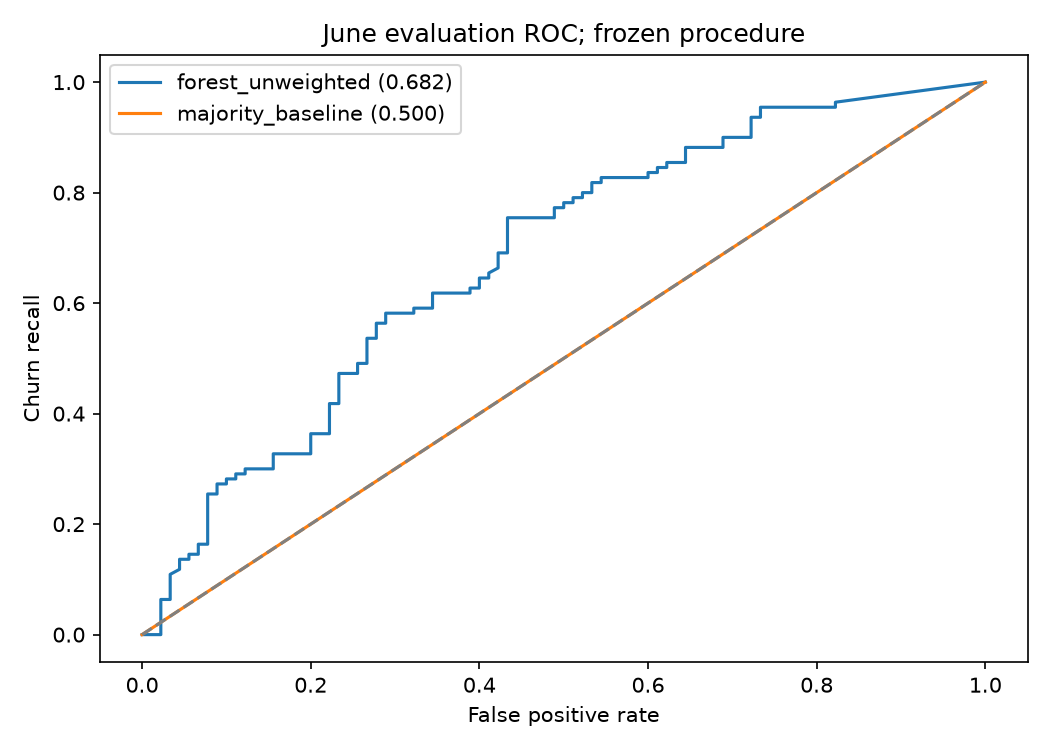

In [6]:
evaluation = generate_evaluation(PREPARATION, MODELS, EVALUATION)
metrics = pd.read_csv(EVALUATION / "evaluation_metrics.csv")
display(metrics.query("scope == 'all'")[
    ["candidate", "customers", "roc_auc", "balanced_accuracy", "accuracy", "f1", "brier_score"]].round(4))
display(Image(filename=str(EVALUATION / "evaluation_roc.png")))

*Figure 4 — synthetic June ROC.* This is a software demonstration using invented outcomes. It is neither the private assessment nor evidence of future operational generalization.

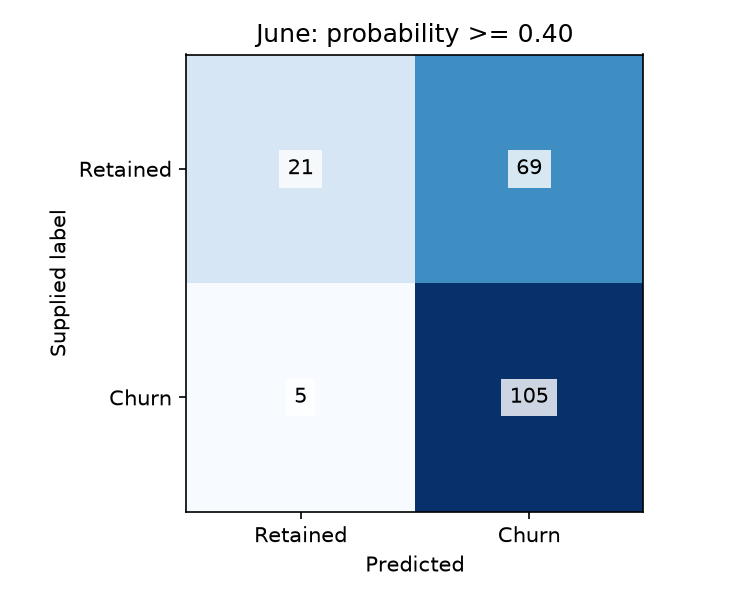

,scope,customers,tn,fp,fn,tp,recall,retained_recall
0,all,200,21,69,5,105,0.9545,0.2333
1,usable,180,5,69,1,105,0.9906,0.0676
2,fallback,20,16,0,4,0,0.0000,1.0000


In [7]:
display(Image(filename=str(EVALUATION / "evaluation_confusion.png")))
display(metrics.loc[metrics.candidate.eq(selection["selected_candidate"]),
    ["scope", "customers", "tn", "fp", "fn", "tp", "recall", "retained_recall"]].round(4))

*Figure 5 — synthetic June errors.* Missing-history customers remain in the assessment and cannot be ranked within their constant-prior subgroup. Any intervention value would also depend on costs, capacity and causal retention benefit.

## 7. Refit and validate the synthetic export

After assessment, relearn vocabulary/preprocessing on all usable labeled cohorts and the conditional prior on all labeled fallback cases. Keep candidate settings and threshold fixed. Score each scoring cohort, average probabilities equally for ambiguous customer IDs, then apply the inclusive cutoff once. The full-label fit has no new holdout score.

In [8]:
final = generate_submission(ROOT / "input", MODELS, FINAL, EVALUATION)
predictions = pd.read_csv(FINAL / "predictions.csv", dtype={"FK_DWH_CUSTOMERS": "string"})
expected = pd.read_csv(PREPARATION / "submission_ids.csv", dtype="string").fk_dwh_customers
validate_submission(predictions, expected)
display(pd.DataFrame({"Export check": list(final["submission"]), "Value": list(final["submission"].values())}))
print("Synthetic export verified; only aggregate evidence is displayed.")
print("CSV SHA-256:", sha256(FINAL / "predictions.csv"))

,Export check,Value
0,customers,241
1,cohort_groups,242
2,usable_customers,217
3,fallback_customers,24
4,usable_cohort_groups,218
5,predicted_churn,214
6,predicted_retained,27
7,multiple_cohort_customers,1


Synthetic export verified; only aggregate evidence is displayed.
CSV SHA-256: 7080cf3805ce3bbaddfa52b7a20a30ac2f347b3082f581b90797fdb31657b06c


## 8. Evidence boundaries

All results in this notebook are synthetic. Historical private-exercise aggregates are recorded separately in `doc/historical_results.md` and cannot be independently reproduced without the undistributed data.

This is fixed-horizon classification, not time-to-event estimation. Source event dates, active-at-cutoff status, historical availability and matured-label dates would be required to establish a deployable backtest or actionable lead time. Missing invoice months do not establish silent disengagement; usage/renewal outcomes would be needed. No annual seasonality, calibrated risk, causal drivers or retention uplift is demonstrated. Small candidate-score differences do not establish statistical superiority.

Each stage writes hash-linked provenance; seeds and single-thread fitting support repeatability. Keep generated inputs/outputs local. See the README and `doc/` for decisions and reproduction commands.